# Titanic Survival Analysis: Exploratory Data Analysis (EDA)

**Project:** InternCircle Project 01
**Name:** (Arya Ghatage)

## Objective
To explore the Titanic passenger dataset using Python and Pandas, clean it, and find which factors were linked to survival.

## Three Questions
1. Did women survive more than men?
2. Did passenger class affect survival rates?
3. Was age associated with survival?

## Dataset
Titanic passenger data from the Seaborn library. Each row is one passenger. The columns include survival, class, sex, age, fare and port of embarkation.

## Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, VS Code, Jupyter Notebook

## Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


## load Dataset

In [26]:
df = sns.load_dataset("titanic")
print("Dataset loaded successfully")
print(df.shape)

Dataset loaded successfully
(891, 15)


## initial Data exploration

In [27]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [28]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [30]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [31]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')

In [32]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [33]:
df["age"] = df["age"].fillna(df.groupby(["pclass", "sex"])["age"].transform("median"))
print("Missing ages after filling:", df["age"].isna().sum())

Missing ages after filling: 0


In [34]:
most_common = df["embarked"].mode()[0]
df["embarked"] = df["embarked"].fillna(most_common)
print("Most common port:", most_common)
print("Missing embarked after filling:", df["embarked"].isna().sum())

Most common port: S
Missing embarked after filling: 0


In [35]:
df = df.drop(columns=["deck"])
print(df.shape)

(891, 14)


In [36]:
dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)


Duplicate rows: 118


**Duplicate check:** 118 rows look identical. The dataset has no passenger ID, so these are most likely different passengers with the same details. They are kept so the survival rates stay accurate.

In [37]:
df.dtypes

survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
embark_town         str
alive               str
alone              bool
dtype: object

In [38]:
df["sex"] = df["sex"].astype("category")
df["embarked"] = df["embarked"].astype("category")
print(df[["sex", "embarked"]].dtypes)

sex         category
embarked    category
dtype: object


## Exploratory Data Analysis
### 1. Survival Rate By Gender

In [39]:
gender_survival = df.groupby("sex").agg(
    passengers=("survived", "count"),
    survivors=("survived", "sum"),
    survival_rate=("survived", "mean")
)
gender_survival["survival_rate"] = (gender_survival["survival_rate"] * 100).round(2)
gender_survival

,passengers,survivors,survival_rate
sex,,,
female,314,233,74.20
male,577,109,18.89


### 2. Survival Rate By Passenger Class

In [40]:
class_survival = df.groupby("pclass").agg(
    passengers=("survived", "count"),
    survivors=("survived", "sum"),
    survival_rate=("survived", "mean")
)
class_survival["survival_rate"] = (class_survival["survival_rate"] * 100).round(2)
class_survival

,passengers,survivors,survival_rate
pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


### 3. Survival Rate By Age Group

In [41]:
age_bins = [0, 12, 18, 35, 60, 100]
age_labels = ["Child (0-12)", "Teen (13-18)", "Young Adult (19-35)", "Adult (36-60)", "Senior (61+)"]
df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels)

age_survival = df.groupby("age_group", observed=True).agg(
    passengers=("survived", "count"),
    survivors=("survived", "sum"),
    survival_rate=("survived", "mean")
)
age_survival["survival_rate"] = (age_survival["survival_rate"] * 100).round(2)
age_survival

,passengers,survivors,survival_rate
age_group,,,
Child (0-12),69,40,57.97
Teen (13-18),70,30,42.86
Young Adult (19-35),514,184,35.80
Adult (36-60),216,83,38.43
Senior (61+),22,5,22.73


## Data Visualization
### chart 1: Survival Count

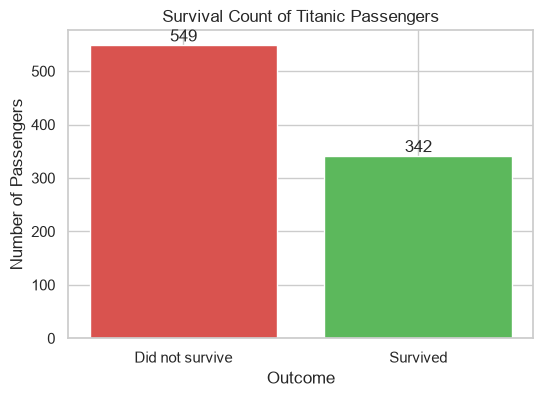

In [42]:
import os
os.makedirs("outputs/charts", exist_ok=True)
sns.set_theme(style="whitegrid")

counts = df["survived"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
bars = plt.bar(["Did not survive", "Survived"], counts.values, color=["#d9534f", "#5cb85c"])
plt.bar_label(bars)
plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Outcome")
plt.ylabel("Number of Passengers")
plt.savefig("outputs/charts/survival_count.png", dpi=150, bbox_inches="tight")
plt.show()

### 2. Survival By Gender

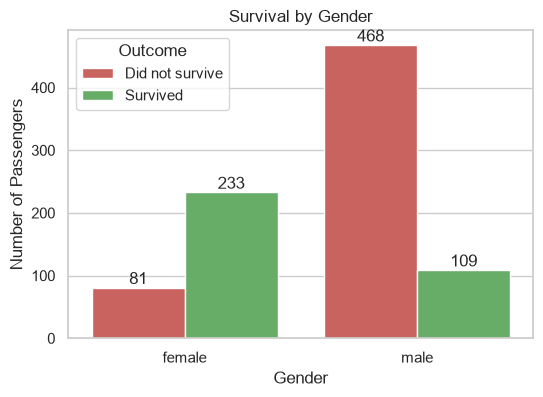

In [43]:
plot_df = df.copy()
plot_df["Outcome"] = plot_df["survived"].map({0: "Did not survive", 1: "Survived"})

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=plot_df, x="sex", hue="Outcome",
                   hue_order=["Did not survive", "Survived"],
                   palette=["#d9534f", "#5cb85c"])
for container in ax.containers:
    ax.bar_label(container)
plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.savefig("outputs/charts/survival_by_gender.png", dpi=150, bbox_inches="tight")
plt.show()

### 3. Survival By Passener Class

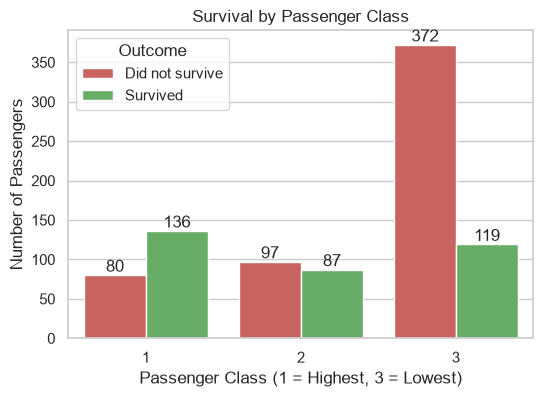

In [44]:
plot_df = df.copy()
plot_df["Outcome"] = plot_df["survived"].map({0: "Did not survive", 1: "Survived"})

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=plot_df, x="pclass", hue="Outcome",
                   hue_order=["Did not survive", "Survived"],
                   palette=["#d9534f", "#5cb85c"])
for container in ax.containers:
    ax.bar_label(container)
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class (1 = Highest, 3 = Lowest)")
plt.ylabel("Number of Passengers")
plt.savefig("outputs/charts/survival_by_class.png", dpi=150, bbox_inches="tight")
plt.show()


### Chart 4: Age Distribution

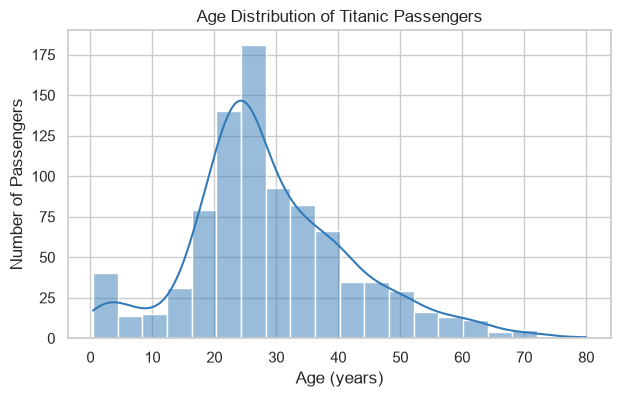

In [45]:
plt.figure(figsize=(7, 4))
sns.histplot(df["age"], bins=20, kde=True, color="#337ab7")
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")
plt.savefig("outputs/charts/age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

###  Chart : Survival Rate By Age Group

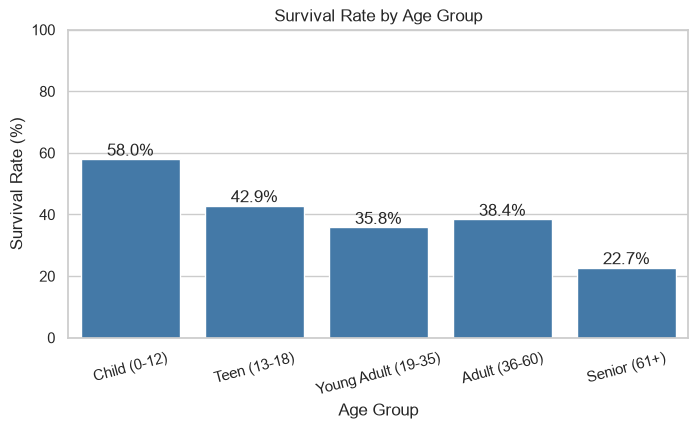

In [46]:
rate_df = age_survival.reset_index()

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=rate_df, x="age_group", y="survival_rate", color="#337ab7")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.savefig("outputs/charts/survival_by_age_group.png", dpi=150, bbox_inches="tight")
plt.show()

## Three Key Findings

In [47]:
# Finding 1: gender
female_rate = df[df["sex"] == "female"]["survived"].mean() * 100
male_rate = df[df["sex"] == "male"]["survived"].mean() * 100
print("FINDING 1 - GENDER")
print(f"Female survival rate: {female_rate:.1f}%")
print(f"Male survival rate: {male_rate:.1f}%")
print(f"Gap: {female_rate - male_rate:.1f} percentage points")

# Finding 2: class
class_rates = df.groupby("pclass")["survived"].mean() * 100
print("\nFINDING 2 - CLASS")
for c, r in class_rates.items():
    print(f"Class {c}: {r:.1f}%")
print(f"Class 1 vs Class 3 gap: {class_rates.loc[1] - class_rates.loc[3]:.1f} percentage points")

# Finding 3: age
age_rates = age_survival["survival_rate"]
print("\nFINDING 3 - AGE")
for group, r in age_rates.items():
    print(f"{group}: {r:.1f}%")
print(f"Highest: {age_rates.idxmax()} ({age_rates.max():.1f}%)")
print(f"Lowest: {age_rates.idxmin()} ({age_rates.min():.1f}%)")

FINDING 1 - GENDER
Female survival rate: 74.2%
Male survival rate: 18.9%
Gap: 55.3 percentage points

FINDING 2 - CLASS
Class 1: 63.0%
Class 2: 47.3%
Class 3: 24.2%
Class 1 vs Class 3 gap: 38.7 percentage points

FINDING 3 - AGE
Child (0-12): 58.0%
Teen (13-18): 42.9%
Young Adult (19-35): 35.8%
Adult (36-60): 38.4%
Senior (61+): 22.7%
Highest: Child (0-12) (58.0%)
Lowest: Senior (61+) (22.7%)


### Finding 1: Did women survive more than men?
Answer: Yes. 74.2% of women survived compared with 18.9% of men, a gap of 55.3 percentage points.

### Finding 2: Did passenger class affect survival?
Answer: Yes. Survival was 63.0% in Class 1, 47.3% in Class 2 and 24.2% in Class 3. First class was 38.8 percentage points higher than third class.

### Finding 3: Was age associated with survival?
Answer: Yes, but less strongly than gender or class. Children (0-12) had the highest survival rate (58.0%) and seniors (61+) had the lowest (22.7%). The other groups were between 35.8% and 42.9%.

## Final Conclusion

### What the dataset revealed
The Titanic dataset has 891 passengers. Overall, 38.4% survived. Survival was not equal across groups.

### Important survival patterns
- **Gender:** 74.2% of women survived compared with 18.9% of men.
- **Class:** survival fell from 63.0% in Class 1 to 24.2% in Class 3.
- **Age:** children (0-12) had the highest survival rate (58.0%), and seniors (61+) had the lowest (22.7%).

### What I learned
I learned how to load data with Pandas, check missing values and duplicates, fill missing values with the median and mode, group data with `groupby()` and `agg()`, make age groups with `pd.cut()`, and show results with Matplotlib and Seaborn charts.

### Limitations
- 177 missing ages (about 20%) were filled with medians, which may hide real age differences.
- The `deck` column was dropped because most of it was missing.
- 118 duplicate-looking rows were kept, since there is no passenger ID.
- This analysis shows patterns, not causes. Gender, class and age are linked to each other.
- The dataset has 891 passengers, so it is only a sample of everyone on board.

In [48]:
print("Overall survival:", round(df["survived"].mean() * 100, 1))
print("Female:", round(df[df["sex"] == "female"]["survived"].mean() * 100, 1))
print("Male:", round(df[df["sex"] == "male"]["survived"].mean() * 100, 1))
print(df.groupby("pclass")["survived"].mean().mul(100).round(1))
print(age_survival["survival_rate"])

Overall survival: 38.4
Female: 74.2
Male: 18.9
pclass
1    63.0
2    47.3
3    24.2
Name: survived, dtype: float64
age_group
Child (0-12)           57.97
Teen (13-18)           42.86
Young Adult (19-35)    35.80
Adult (36-60)          38.43
Senior (61+)           22.73
Name: survival_rate, dtype: float64
